## fill the missing categorical value using mode value

In [36]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
df=pd.read_csv('titanic_data_updated.csv')
df.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [37]:
X=df.drop(['PassengerId','Name','Ticket'],axis=1)
X.head(3)

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,no,third,male,22.0,1,0,7.2500,NaN,S
1,yes,first,female,38.0,1,0,71.2833,C85,C
2,yes,third,female,26.0,0,0,7.9250,NaN,S


In [38]:
y=df['Survived']
y.head(3)

0     no
1    yes
2    yes
Name: Survived, dtype: object

In [39]:
X.isnull().sum()

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Cabin       687
Embarked      2
dtype: int64

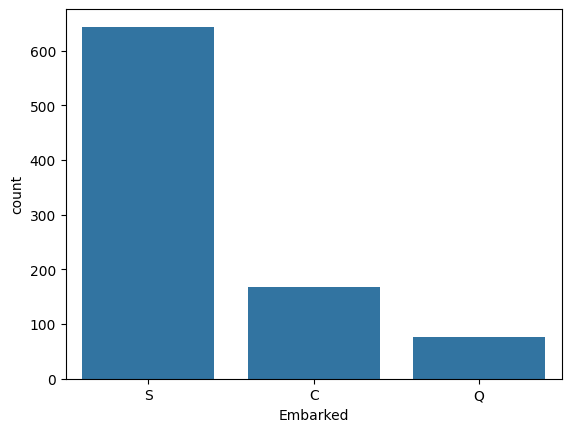

In [40]:
sns.countplot(data=df,x='Embarked')
plt.show()

In [41]:
y.isnull().sum()

np.int64(0)

In [42]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
X_train.isnull().sum()

Survived      0
Pclass        0
Sex           0
Age         140
SibSp         0
Parch         0
Fare          0
Cabin       553
Embarked      2
dtype: int64

## implement mode value

In [44]:
mode_imputor=SimpleImputer(missing_values=np.nan,strategy='most_frequent')
mode_imputor.fit(X_train[['Embarked']])
X_train['Embarked']=mode_imputor.transform(X_train[['Embarked']]).ravel()
X_test['Embarked']=mode_imputor.transform(X_test[['Embarked']]).ravel()
X_train.isnull().sum()

Survived      0
Pclass        0
Sex           0
Age         140
SibSp         0
Parch         0
Fare          0
Cabin       553
Embarked      0
dtype: int64

In [45]:
X_test.isnull().sum()

Survived      0
Pclass        0
Sex           0
Age          37
SibSp         0
Parch         0
Fare          0
Cabin       134
Embarked      0
dtype: int64